In [13]:
# Install and load necessary packages
# install.packages(c("picante", "phytools"))

library(vegan)
library(ggplot2)
library(ape)
library(picante)
library(phytools)

# Set seed for reproducibility
set.seed(123)

# Generate sample microbial community data (OTU table)
num_samples <- 20
num_taxa <- 50


# Generate synthetic OTU table (Operational Taxonomic Unit counts)
otu_table <- matrix(rpois(num_samples * num_taxa, lambda = 10), nrow = num_samples, ncol = num_taxa)
rownames(otu_table) <- paste0("Sample", 1:num_samples)
colnames(otu_table) <- paste0("Taxon", 1:num_taxa)

# Generate a random phylogenetic tree with matching taxa labels
taxa_labels <- colnames(otu_table)
phylo_tree <- rtree(n = num_taxa, tip.label = taxa_labels)

# Generate synthetic environmental data
env_data <- data.frame(
  SampleID = rownames(otu_table),
  NutrientLevel = runif(num_samples, min = 0, max = 100),  # Continuous variable
  Temperature = rnorm(num_samples, mean = 20, sd = 5),     # Continuous variable
  Location = rep(c("SiteA", "SiteB"), each = num_samples / 2)  # Categorical variable
)

In [14]:
# Add a pseudocount to avoid zeros
otu_table_pseudo <- otu_table + 1

# Centered Log-Ratio (CLR) Transformation
otu_clr <- t(apply(otu_table_pseudo, 1, function(x) log(x) - mean(log(x))))

# Compute Aitchison distance (Euclidean distance on CLR-transformed data)
aitchison_dist <- dist(otu_clr)

# Perform PCoA
pcoa_results <- cmdscale(aitchison_dist, eig = TRUE, k = 2)
scores <- as.data.frame(pcoa_results$points)
colnames(scores) <- c("PCoA1", "PCoA2")
scores$SampleID <- rownames(scores)

# Merge with environmental data
scores <- merge(scores, env_data, by = "SampleID")

In [4]:
# Add a pseudocount to avoid zeros
otu_table_pseudo <- otu_table + 1

# Centered Log-Ratio (CLR) Transformation
otu_clr <- t(apply(otu_table_pseudo, 1, function(x) log(x) - mean(log(x))))

# Compute Aitchison distance (Euclidean distance on CLR-transformed data)
aitchison_dist <- dist(otu_clr)

# Perform PCoA
pcoa_results <- cmdscale(aitchison_dist, eig = TRUE, k = 2)
scores <- as.data.frame(pcoa_results$points)
colnames(scores) <- c("PCoA1", "PCoA2")
scores$SampleID <- rownames(scores)

# Merge with environmental data
scores <- merge(scores, env_data, by = "SampleID")

In [17]:

# Fit environmental variables onto the ordination
envfit_results <- envfit(pcoa_results, env_data[, -1], permutations = 999) # Exclude SampleID column

# Extract fitted vectors and their significance (p-values)
significant_envfit <- as.data.frame(envfit_results$vectors$arrows) # Get vector coordinates
significant_envfit$pvals <- envfit_results$vectors$pvals            # Get p-values
significant_envfit <- significant_envfit[significant_envfit$pvals <= 0.05, ] # Filter by significance
significant_envfit$Variable <- rownames(significant_envfit)         # Label the variables

In [15]:
if (!all(colnames(otu_table) %in% phylo_tree$tip.label)) {
  stop("Taxa names in the OTU table do not match the phylogenetic tree tip labels")
}

In [16]:
# Calculate betaMNTD between communities
beta_mntd_obs <- comdistnt(otu_table, cophenetic(phylo_tree), abundance.weighted = TRUE)

# Generate null model and calculate betaNTI
reps <- 999
beta_mntd_null <- array(NA, dim = c(nrow(otu_table), nrow(otu_table), reps))

for (i in 1:reps) {
  # Randomize OTU table
  otu_table_rand <- t(apply(otu_table, 1, sample))
  # Calculate betaMNTD for randomized data
  beta_mntd_null[,,i] <- as.matrix(comdistnt(otu_table_rand, cophenetic(phylo_tree), abundance.weighted = TRUE))
}

# Calculate mean and SD of null distributions
beta_mntd_mean <- apply(beta_mntd_null, c(1,2), mean, na.rm = TRUE)
beta_mntd_sd <- apply(beta_mntd_null, c(1,2), sd, na.rm = TRUE)

# Calculate betaNTI
beta_nti <- (beta_mntd_obs - beta_mntd_mean) / beta_mntd_sd

# Convert betaNTI to a long format for plotting
beta_nti_df <- as.data.frame(as.table(as.matrix(beta_nti)))
colnames(beta_nti_df) <- c("SampleID1", "SampleID2", "betaNTI")

ERROR: Error in match.comm.dist(comm, dis): Community data set lacks taxa (column) names, these are required to match distance matrix and community data


In [37]:
significant_envfit

Dim1,Dim2,pvals
<dbl>,<dbl>,<dbl>


In [35]:
p <- ggplot(scores, aes(x = PCoA1, y = PCoA2)) +
  geom_point(aes(color = NutrientLevel, shape = Location), size = 3) +
  scale_color_gradient(low = "blue", high = "red") +
  theme_minimal() +
  labs(x = paste0("PCoA1 (", round(pcoa_results$eig[1] / sum(pcoa_results$eig) * 100, 2), "%)"),
       y = paste0("PCoA2 (", round(pcoa_results$eig[2] / sum(pcoa_results$eig) * 100, 2), "%)"),
       color = "Nutrient Level",
       shape = "Location")

# Add environmental vectors if there are significant ones
# if (nrow(significant_envfit) > 0) {
  p <- p + geom_segment(data = significant_envfit, aes(x = 0, y = 0, xend = Dim1, yend = Dim2),
                        arrow = arrow(length = unit(0.3, "cm")), color = "black") +
    geom_text(data = significant_envfit, aes(x = Dim1 * 1.1, y = Dim2 * 1.1, label = Variable),
              size = 4, hjust = 0.5)
# }

In [36]:
print(p)


ERROR: [1m[33mError[39m in `geom_text()`:[22m
[1m[22m[33m![39m Problem while computing aesthetics.
[36mi[39m Error occurred in the 3rd layer.
[1mCaused by error:[22m
[33m![39m object 'Variable' not found


Warning message in beta_mntd_obs - beta_mntd_mean:
"longer object length is not a multiple of shorter object length"
Not enough data to generate heatmap (requires at least 2 rows and 2 columns).



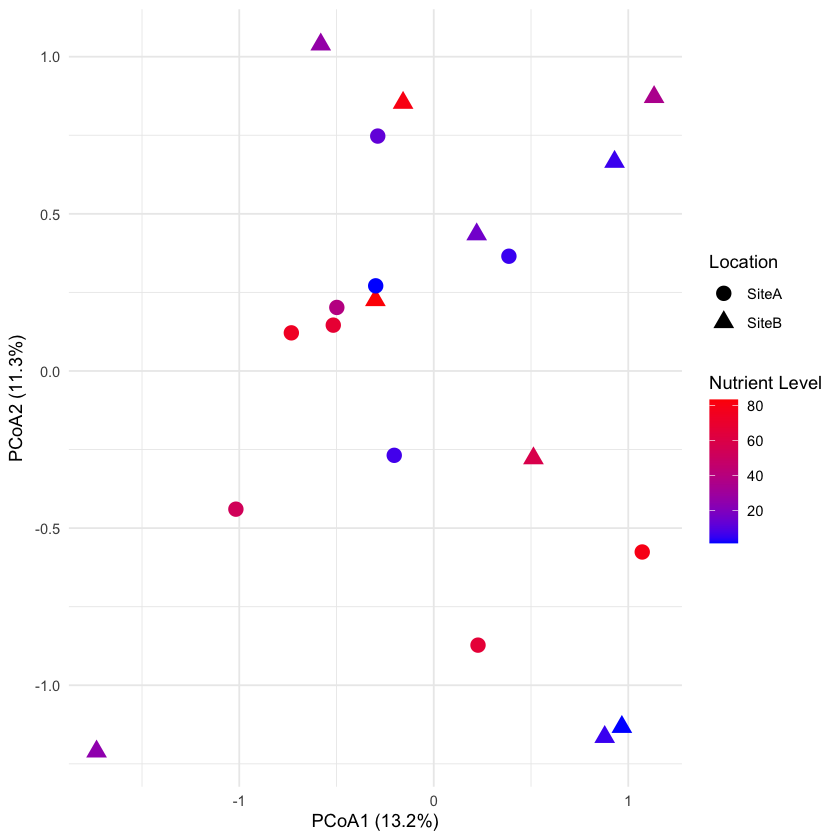

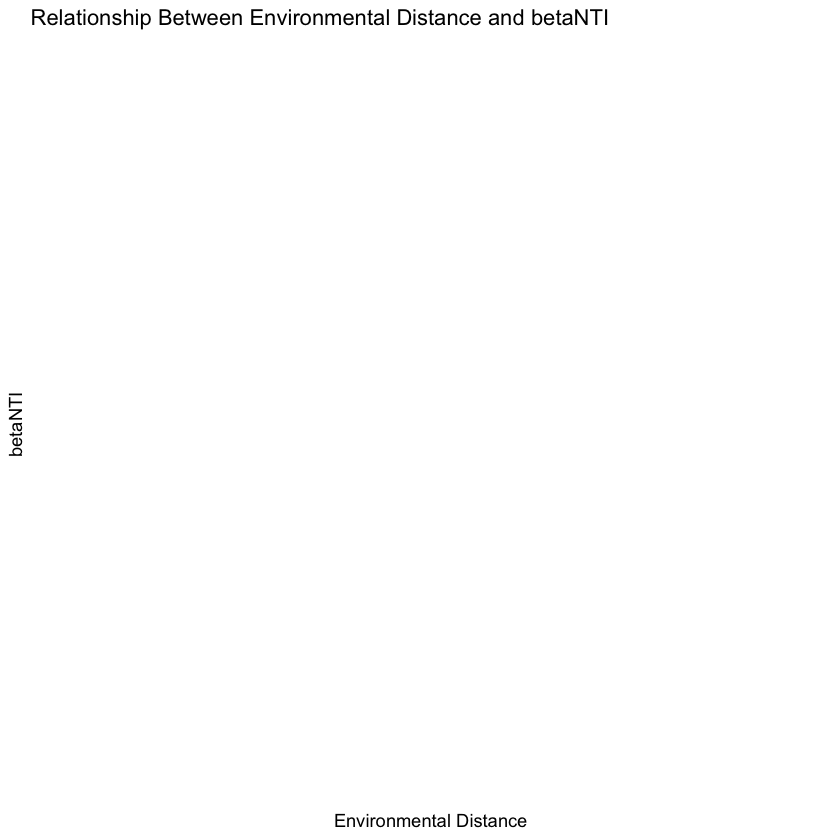

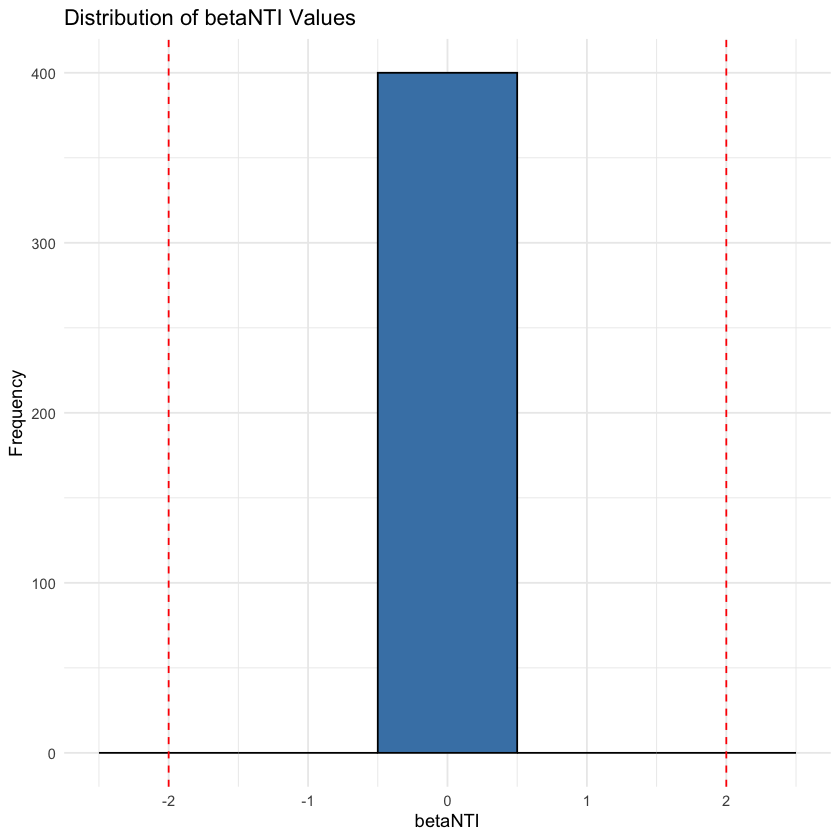

In [31]:
# Import necessary libraries
library(vegan)
library(ggplot2)
library(ape)
library(picante)
library(phytools)
library(pheatmap)

# Set seed for reproducibility
set.seed(123)

# Generate synthetic OTU table (Operational Taxonomic Unit counts)
num_samples <- 20
num_taxa <- 50
otu_table <- matrix(rpois(num_samples * num_taxa, lambda = 10), nrow = num_samples, ncol = num_taxa)
rownames(otu_table) <- paste0("Sample", 1:num_samples)
colnames(otu_table) <- paste0("Taxon", 1:num_taxa)

# Generate synthetic environmental data
env_data <- data.frame(
  SampleID = rownames(otu_table),
  NutrientLevel = runif(num_samples, min = 0, max = 100),  # Continuous variable
  Temperature = rnorm(num_samples, mean = 20, sd = 5),     # Continuous variable
  Location = rep(c("SiteA", "SiteB"), each = num_samples / 2)  # Categorical variable
)

# Perform CLR Transformation for compositional data
clr_transform <- function(matrix) {
  log_matrix <- log(matrix + 1)  # Add pseudocount to avoid log(0)
  geometric_mean <- exp(rowMeans(log_matrix))
  sweep(log_matrix, 1, log(geometric_mean), FUN = "-")
}

otu_clr <- clr_transform(otu_table)

# Compute Aitchison distance (Euclidean distance on CLR-transformed data)
aitchison_dist <- dist(otu_clr)

# Perform PCoA
pcoa_results <- cmdscale(aitchison_dist, eig = TRUE, k = 2)
scores <- as.data.frame(pcoa_results$points)
colnames(scores) <- c("PCoA1", "PCoA2")
scores$SampleID <- rownames(scores)

# Merge with environmental data
scores <- merge(scores, env_data, by = "SampleID")

# Fit environmental variables onto the ordination
envfit_results <- envfit(pcoa_results, env_data[, -1], permutations = 999) # Exclude SampleID column

# Extract significant environmental vectors
significant_envfit <- as.data.frame(envfit_results$vectors$arrows)
significant_envfit$pvals <- envfit_results$vectors$pvals
significant_envfit <- significant_envfit[significant_envfit$pvals <= 0.05, , drop = FALSE]
if (nrow(significant_envfit) > 0) {
  significant_envfit$Variable <- rownames(significant_envfit)
}

# Create the ordination plot with environmental vectors
p <- ggplot(scores, aes(x = PCoA1, y = PCoA2)) +
  geom_point(aes(color = NutrientLevel, shape = Location), size = 4) +
  scale_color_gradient(low = "blue", high = "red") +
  theme_minimal() +
  labs(x = paste0("PCoA1 (", round(pcoa_results$eig[1] / sum(pcoa_results$eig) * 100, 1), "%)"),
       y = paste0("PCoA2 (", round(pcoa_results$eig[2] / sum(pcoa_results$eig) * 100, 1), "%)"),
       color = "Nutrient Level",
       shape = "Location")

# Add environmental vectors if there are significant ones
if (nrow(significant_envfit) > 0) {
  p <- p + geom_segment(data = significant_envfit, aes(x = 0, y = 0, xend = Dim1, yend = Dim2),
                        arrow = arrow(length = unit(0.3, "cm")), color = "black") +
    geom_text(data = significant_envfit, aes(x = Dim1 * 1.1, y = Dim2 * 1.1, label = Variable),
              size = 4, hjust = 0.5)
}

# Print the PCoA ordination plot
print(p)

# --- Additional Figures ---

# 1. Heatmap of betaNTI Values
# Generate a random phylogenetic tree for the taxa
phylo_tree <- rtree(num_taxa)

# Ensure the OTU table and phylogenetic tree have matching taxa names
colnames(otu_table) <- phylo_tree$tip.label

# Calculate betaMNTD between communities
beta_mntd_obs <- comdistnt(otu_table, cophenetic(phylo_tree), abundance.weighted = TRUE)

# Generate null model and calculate betaNTI
reps <- 999
beta_mntd_null <- array(NA, dim = c(nrow(otu_table), nrow(otu_table), reps))
for (i in 1:reps) {
  otu_table_rand <- t(apply(otu_table, 1, sample))
  colnames(otu_table_rand) <- colnames(otu_table)
  beta_mntd_null[,,i] <- as.matrix(comdistnt(otu_table_rand, cophenetic(phylo_tree), abundance.weighted = TRUE))
}

# Calculate mean and SD of null distributions
beta_mntd_mean <- apply(beta_mntd_null, c(1,2), mean, na.rm = TRUE)
beta_mntd_sd <- apply(beta_mntd_null, c(1,2), sd, na.rm = TRUE)

# Calculate betaNTI
beta_nti <- (beta_mntd_obs - beta_mntd_mean) / beta_mntd_sd

# Remove NA/NaN/Inf values from betaNTI matrix
beta_nti[is.na(beta_nti) | is.infinite(beta_nti)] <- 0

# Filter out rows and columns that are entirely zeros
beta_nti_matrix <- as.matrix(beta_nti)
beta_nti_matrix <- beta_nti_matrix[rowSums(beta_nti_matrix != 0) > 0, colSums(beta_nti_matrix != 0) > 0]

# Plot heatmap of betaNTI Values if matrix has at least 2 rows and 2 columns
if (nrow(beta_nti_matrix) >= 2 && ncol(beta_nti_matrix) >= 2) {
  pheatmap(beta_nti_matrix, cluster_rows = TRUE, cluster_cols = TRUE, color = colorRampPalette(c("blue", "white", "red"))(50), main = "Heatmap of betaNTI Values")
} else {
  message("Not enough data to generate heatmap (requires at least 2 rows and 2 columns).")
}

# 2. Scatter Plot of Environmental Distance vs. betaNTI
# Calculate environmental distance
env_variables <- env_data[, c("NutrientLevel", "Temperature")]
rownames(env_variables) <- env_data$SampleID
env_dist <- as.matrix(dist(env_variables))

# Convert to long format
env_dist_df <- as.data.frame(as.table(env_dist))
colnames(env_dist_df) <- c("SampleID1", "SampleID2", "EnvDistance")

# Merge with betaNTI data
beta_nti_df <- as.data.frame(as.table(beta_nti))
colnames(beta_nti_df) <- c("SampleID1", "SampleID2", "betaNTI")

beta_nti_env <- merge(beta_nti_df, env_dist_df, by = c("SampleID1", "SampleID2"))

# Plot the scatter plot
ggplot(beta_nti_env, aes(x = EnvDistance, y = betaNTI)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", color = "blue", se = TRUE) +
  theme_minimal() +
  labs(x = "Environmental Distance", y = "betaNTI", title = "Relationship Between Environmental Distance and betaNTI")

# 3. Histogram of betaNTI Distribution
# Plot the histogram
ggplot(beta_nti_df, aes(x = betaNTI)) +
  geom_histogram(binwidth = 1, fill = "steelblue", color = "black") +
  geom_vline(xintercept = c(-2, 2), linetype = "dashed", color = "red") +
  theme_minimal() +
  labs(x = "betaNTI", y = "Frequency", title = "Distribution of betaNTI Values")
